--- Statistiques descriptives (Nombre de mots par fiche) ---
count      526.0
mean      2602.0
std       4035.0
min         47.0
25%        746.0
50%       1522.0
75%       2828.0
90%       5492.0
95%       7943.0
max      41624.0
Name: word_count, dtype: float64

--- Estimation des Tokens ---
Médiane estimée : 2132 tokens
90e percentile estimé : 7688 tokens


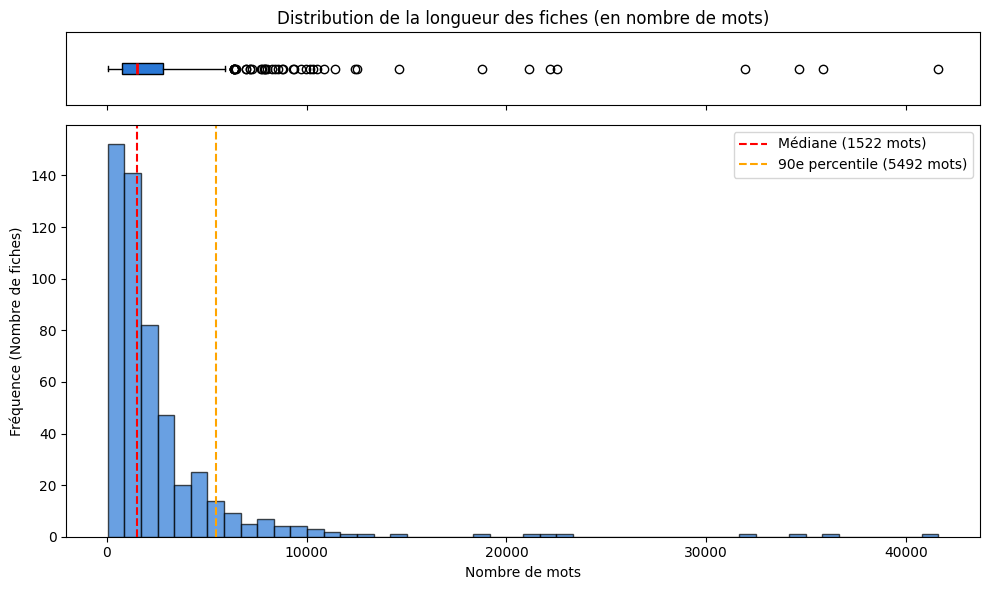

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Lecture du fichier Parquet
df = pd.read_parquet("/corpus.parquet")

# 2. Calcul du nombre de mots pour chaque fiche
# On se base sur les mots car votre fonction split_words() découpe sur les espaces
df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))

# 3. Calcul de l'estimation en tokens (règle empirique : 1 mot français ≈ 1.4 tokens)
df['token_estimate'] = df['word_count'] * 1.4

# 4. Affichage des statistiques descriptives
print("--- Statistiques descriptives (Nombre de mots par fiche) ---")
stats = df['word_count'].describe(percentiles=[.25, .5, .75, .90, .95])
print(stats.round(0))

print(f"\n--- Estimation des Tokens ---")
print(f"Médiane estimée : {df['token_estimate'].median():.0f} tokens")
print(f"90e percentile estimé : {df['token_estimate'].quantile(0.90):.0f} tokens")

# 5. Création de la figure Matplotlib avec 2 sous-graphiques (boxplot en haut, histogramme en bas)
fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, gridspec_kw={"height_ratios": (.15, .85)}, figsize=(10, 6))

# Boîte à moustaches (boxplot) en haut
ax_box.boxplot(df['word_count'], vert=False, patch_artist=True,
               boxprops=dict(facecolor='#2a78d6', color='black'),
               medianprops=dict(color='red', linewidth=2))
ax_box.set_yticks([]) # Cacher les ticks de l'axe Y pour la boîte
ax_box.set_title("Distribution de la longueur des fiches (en nombre de mots)")

# Histogramme en bas
ax_hist.hist(df['word_count'], bins=50, color='#2a78d6', edgecolor='black', alpha=0.7)
ax_hist.set_xlabel("Nombre de mots")
ax_hist.set_ylabel("Fréquence (Nombre de fiches)")

# Lignes verticales pour repères visuels
median_val = df['word_count'].median()
p90_val = df['word_count'].quantile(0.90)

ax_hist.axvline(median_val, color='red', linestyle='dashed', linewidth=1.5, label=f'Médiane ({median_val:.0f} mots)')
ax_hist.axvline(p90_val, color='orange', linestyle='dashed', linewidth=1.5, label=f'90e percentile ({p90_val:.0f} mots)')
ax_hist.legend()

# Ajustement de l'affichage
plt.tight_layout()
plt.show()

In [2]:
from sentence_transformers import SentenceTransformer
#sentence-transformers/paraphrase-multilingual-MiniLM-L12-v

class Embedder:
    def __init__(self, model_name="intfloat/multilingual-e5-small"):
        """
        Initialise le modèle d'embedding multilingue.
        Les modèles E5 nécessitent souvent l'ajout du préfixe "query: " pour les questions
        et "passage: " pour les documents, mais la bibliothèque sentence-transformers
        gère cela ou s'adapte très bien en mode symétrique.
        """
        self.model = SentenceTransformer(model_name)

    def encode_chunks(self, texts):
        """
        Encode une liste de textes en vecteurs.
        La normalisation à 1 est maintenue pour le calcul de similarité cosinus[cite: 3].
        """
        # Pour les modèles de la famille E5, il est recommandé de préfixer les documents
        # dans la base de données.
        formatted_texts = [f"passage: {text}" for text in texts]
        embeddings = self.model.encode(formatted_texts, normalize_embeddings=True)
        return embeddings.tolist()

    def encode_query(self, query):
        """
        Encode spécifiquement la question de l'utilisateur.
        """
        formatted_query = f"query: {query}"
        return self.model.encode([formatted_query], normalize_embeddings=True).tolist()[0]

In [3]:
# src/rag_assistant/chunking.py

# Paramètres ajustés suite à l'analyse statistique du corpus Service-Public
SIZE = 150
OVERLAP = 30

def split_words(n_words, size=SIZE, overlap=OVERLAP):
    """
    Retourne une liste de positions (start, end) pour les chunks de mots.
    """
    step = size - overlap
    return [(i, min(i + size, n_words)) for i in range(0, max(1, n_words), step)]

def chunk_document(doc_row):
    """
    Découpe une fiche issue du fichier Parquet en chunks.
    """
    text = doc_row.get("text", "")
    if not text:
        return []

    words = text.split()
    chunks = []

    # En-tête enrichi avec le thème pour donner un maximum de contexte administratif
    theme = doc_row.get("theme", "")
    title = doc_row.get("title", "Sans titre")
    date = doc_row.get("date", "Date inconnue")
    header = f"[{theme}] {title} (MàJ: {date})"

    for k, (start, end) in enumerate(split_words(len(words))):
        body = " ".join(words[start:end])

        chunks.append({
            "chunk_id": f"{doc_row['doc_id']}#{k}",
            "doc_id": doc_row["doc_id"],
            "date": date,
            "title": title,
            "theme": theme,
            "start": start,
            "end": end,
            "body": body,
            "text": f"{header}\n{body}" # Le texte final qui sera encodé
        })
    return chunks

In [ ]:
!pip install rank-bm25

In [4]:
# src/rag_assistant/ingest.py
import pandas as pd
import chromadb
#from src.rag_assistant.chunking import chunk_document
#from src.rag_assistant.embedding import Embedder

class IngestionPipeline:
    def __init__(self, persist_directory="/chroma_db"):
        self.embedder = Embedder()

        # Si persist_directory est None, on utilise une base en mémoire pour les tests
        if persist_directory is None:
            print("Mode test : utilisation de ChromaDB en mémoire (EphemeralClient).")
            self.chroma_client = chromadb.EphemeralClient()
        else:
            self.chroma_client = chromadb.PersistentClient(path=persist_directory)

        # Nettoyage robuste
        try:
            self.chroma_client.delete_collection(name="rag_sp_documents")
        except Exception:
            pass

        self.collection = self.chroma_client.create_collection(name="rag_sp_documents")
        self.docstore = {}

    def ingest_parquet(self, parquet_path="/corpus.parquet"):
        # ... (Le reste de la méthode ingest_parquet reste strictement identique)
        print(f"Lecture du corpus depuis {parquet_path}...")
        df = pd.read_parquet(parquet_path)

        all_chunks = []
        for row in df.to_dict(orient="records"):
            all_chunks.extend(chunk_document(row))

        print(f"Encodage de {len(all_chunks)} chunks (avec préfixe 'passage:')...")
        texts = [c["text"] for c in all_chunks]

        embeddings = self.embedder.encode_chunks(texts)

        ids = [c["chunk_id"] for c in all_chunks]
        metadatas = [{
            "doc_id": c["doc_id"],
            "date": c["date"],
            "title": c["title"],
            "theme": c["theme"]
        } for c in all_chunks]

        print("Insertion dans ChromaDB et le docstore (BM25)...")
        batch_size = 5000
        for i in range(0, len(ids), batch_size):
            self.collection.add(
                ids=ids[i:i+batch_size],
                embeddings=embeddings[i:i+batch_size],
                documents=texts[i:i+batch_size],
                metadatas=metadatas[i:i+batch_size]
            )

        for chunk in all_chunks:
            self.docstore[chunk["chunk_id"]] = chunk

        print(f"Ingestion terminée : {len(all_chunks)} chunks indexés.")

In [ ]:
pip install rank_bm25

In [5]:
# src/rag_assistant/retrieval.py
import re
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder

STOPWORDS = set(
    "a abord absolument afin ah ai aie aient aies ailleurs ainsi ait allaient allo allons allô alors "
    "anterieur anterieure anterieures ap apres après as assez attendu au aucucun aucune aujourd "
    "aujourd'hui aupres auquel aura auraient aurais aurait auras aurez auriez aurions aurons auront "
    "aussi autre autrefois autrement autres autrui aux auxquelles auxquels avaient avais avait avant "
    "avec avoir avons ayant ayez b bah bas basee bat beau beaucoup bien bigre boum bravo brrr c car "
    "ce ceci cela celle celle-ci celle-là celles celles-ci celles-là celui celui-ci celui-là cent "
    "cependant certain certaine certaines certains certes ces cet cette ceux ceux-ci ceux-là chacun "
    "chacune chaque cher chers chez chiche chut ci cinq cinquantaine cinquante cinquantième cinquième "
    "clac clic combien comme comment comparable comparables compris concernant contre couic crac d da "
    "dans de debout dedans dehors deja delà depuis dernier derniere derriere derrière des desormais "
    "desquelles desquels dessous dessus deux deuxième deuxièmement devant devers devra different "
    "differentes differents différent différente différentes différents dire directe directement dit "
    "dite dits divers diverse diverses dix dix-huit dixième dix-neuf dix-sept doigt doite doits donc "
    "dont douze douzième d'un d'une eau effet egale egalement egales "
    "eh elle elle-même elles elles-mêmes en encore enfin entre envers environ es est et etait etaient "
    "etais etait etant etc ete etee etees etes etait etant eu eue eues euh eurent eus eusse eussent "
    "eusses eussiez eussions eut eux eux-mêmes exactement excepté extensif extreme extremement f fi "
    "flac floc font g gens h ha hé hein hem hep hi ho holà hop hormis hors hou houp hue hui huit "
    "huitième hurrah i il ils importe j je jusqu jusque k l la laissez laquelle las le lequel les "
    "lesquelles lesquels leur leurs long longtemps lors lorsque lui lui-meme lui-même m ma maint "
    "maintenant mais malgre malgre me meme memes merci mes mien mienne miennes miens mille mince "
    "moi moi-meme moi-même moindre moins mon moyennant multiple multiples même mêmes n na naturel "
    "naturelle naturelles naturels ne neanmoins necessaire necessairement neuf neuvième ni nombreuses "
    "nombreux non nos notamment notre nous nous-mêmes nouveau nul néanmoins nôtre nôtres o oh ohé "
    "ollé olé on ont onze onzième ore ou ouf oui ouï où p paf pan par parce parfois parle parlent "
    "parler parmi parseme partant particulier particuliere particulierement pas passé pendant pense "
    "permet personne peu peut peuvent peux pff pfft pfut pif pire plein plouf plus plusieurs plutôt "
    "possessif possesifs possible possibles pouah pour pourquoi pourrais pourrait pouvait prealable "
    "precisement premier première premièrement pres probable probante procedant proche près psitt "
    "pu puisque q qu quand quant quanta quant-à-soi quarante quatorze quatre quatre-vingt quatrième "
    "quatrièmement que quel quelconque quelle quelles quelque quelques quelqu'un quels qui quiconque "
    "quinze quoi quoique r revoici revoilà rien s sa sacrebleu sans sapristi sauf se seize selon "
    "sept septième sera seraient serais serait seras serez seriez serions serons seront ses seulement "
    "si sien sienne siennes siens sinon six sixième soi soi-même soit soixante son sont sous souvent "
    "specifique specifiques speculatif stop strict stricte strictement subordonnet suffisant "
    "suffisante suffit suis suit suivant suivante suivantes suivants superieur superieure superieures "
    "superieurs sur surcroît t ta tac tant tard te tel telle tellement telles tels tenant tend tes "
    "tic tien tienne tiennes tiens toc toi toi-même ton touchant toujours tous tout toute "
    "toutefois toutes treize trente tres trois troisième troisièmement trop très tsoin tsouin tu "
    "té u un une unes uniformement unique uniques uns v va vais vas vers via vif vifs vingt vivat "
    "voici voilà vont vos votre vous vous-mêmes vu vé vôtre vôtres w x y z zut à â ça è é ê ë î ï ô "
    "ö û ü ù".split()
)

def tokenize_fr(text):
    return [
        w for w in re.findall(r"[a-z0-9àâçéèêëîïôûùüÿñæœ]+(?:\.[0-9]+)?%?", text.lower())
        if w not in STOPWORDS
    ]

def rrf(rankings, k=60, depth=30):
    """
    Fusion des rangs (RRF).
    La profondeur (depth) est augmentée à 30 pour s'adapter à la taille de la base[cite: 3].
    """
    scores = {}
    for ranking in rankings:
        for rank, chunk_id in enumerate(ranking[:depth], start=1):
            scores[chunk_id] = scores.get(chunk_id, 0.0) + (1.0 / (k + rank))

    return sorted(scores.keys(), key=lambda x: scores[x], reverse=True)

class Retriever:
    # Remplacement par un modèle cross-encoder multilingue performant sur le français
    def __init__(self, ingestion_pipeline, reranker_model="cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"):
        self.collection = ingestion_pipeline.collection
        self.embedder = ingestion_pipeline.embedder
        self.docstore = ingestion_pipeline.docstore

        self.chunks_list = list(self.docstore.values())
        self.tokens = [tokenize_fr(c["text"]) for c in self.chunks_list]
        self.bm25 = BM25Okapi(self.tokens) if self.tokens else None

        self.reranker = CrossEncoder(reranker_model)

    def dense_search(self, query, top_n=30):
        # On utilise encode_query pour ajouter le préfixe "query: " propre au modèle E5
        query_vector = self.embedder.encode_query(query)
        results = self.collection.query(
            query_embeddings=[query_vector],
            n_results=top_n
        )
        return results['ids'][0]

    def bm25_search(self, query, top_n=30):
        if not self.bm25: return []
        query_tokens = tokenize_fr(query)
        scores = self.bm25.get_scores(query_tokens)

        ranked_indices = sorted(range(len(scores)), key=lambda i: scores[i], reverse=True)
        return [self.chunks_list[i]["chunk_id"] for i in ranked_indices[:top_n]]

    def hybrid_search(self, query, depth=30):
        dense_ranking = self.dense_search(query, top_n=depth)
        bm25_ranking = self.bm25_search(query, top_n=depth)

        return rrf([dense_ranking, bm25_ranking], k=60, depth=depth)

    def retrieve_and_rerank(self, query, top_k=4, pre_k=30):
        candidate_ids = self.hybrid_search(query, depth=pre_k)
        if not candidate_ids:
            return []

        candidates = [self.docstore[cid] for cid in candidate_ids]

        # Re-ranking via le Cross-Encoder[cite: 3]
        pairs = [[query, c["text"]] for c in candidates]
        scores = self.reranker.predict(pairs)

        ranked_candidates = [c for _, c in sorted(zip(scores, candidates), key=lambda x: x[0], reverse=True)]
        return ranked_candidates[:top_k]

Tests

In [ ]:
# Plus besoin d'importer depuis 'src' car la fonction est définie localement dans le notebook
# from src.rag_assistant.chunking import chunk_document

# Fausse ligne issue du fichier Parquet (environ 50 mots)
mock_row = {
    "doc_id": "F12345",
    "title": "Renouvellement du passeport",
    "date": "2026-10-14",
    "text": "Pour renouveler votre passeport, vous devez acheter un timbre fiscal. " * 10
}

chunks = chunk_document(mock_row)

print(f"--- TEST CHUNKING ---")
print(f"Nombre de chunks générés : {len(chunks)}")
print(f"ID du premier chunk : {chunks[0]['chunk_id']}")
print(f"En-tête généré : {chunks[0]['text'].split(':')[0]}")
print(f"Texte du premier chunk : {chunks[0]['body'][:50]}...\n")

--- TEST CHUNKING ---
Nombre de chunks générés : 1
ID du premier chunk : F12345#0
En-tête généré : [] Renouvellement du passeport (MàJ
Texte du premier chunk : Pour renouveler votre passeport, vous devez achete...



In [ ]:
# Plus besoin d'importer depuis 'src' car la classe Embedder est définie localement
# from src.rag_assistant.embedding import Embedder

print(f"--- TEST EMBEDDING ---")
embedder = Embedder()
textes_test = ["Ceci est une phrase de test.", "Voici un autre document."]
vecteurs = embedder.encode_chunks(textes_test)

print(f"Nombre de vecteurs générés : {len(vecteurs)}")
print(f"Dimension du vecteur : {len(vecteurs[0])} (attendu: 384)")
print(f"Aperçu du vecteur 1 : {vecteurs[0][:3]}...\n")

--- TEST EMBEDDING ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Nombre de vecteurs générés : 2
Dimension du vecteur : 384 (attendu: 384)
Aperçu du vecteur 1 : [0.020970916375517845, -0.006224636919796467, -0.07069438695907593]...



In [6]:
import os
import pandas as pd
import shutil

# --- 1. CRÉATION D'UN JEU DE DONNÉES DE TEST ---
print("--- 1. CRÉATION DU JEU DE TEST ---")
df_test = pd.DataFrame([
    {
        "doc_id": "F1000",
        "theme": "Papiers - Citoyenneté - Élections",
        "title": "Renouvellement du passeport",
        "date": "2026-05-12",
        "text": ("Pour renouveler votre passeport, vous devez acheter un timbre fiscal de 86 euros. "
                 "Vous devez également fournir une photo d'identité récente de moins de 6 mois "
                 "et un justificatif de domicile à votre nom. ") * 5
    },
    {
        "doc_id": "F2000",
        "theme": "Logement",
        "title": "Aide personnalisée au logement (APL)",
        "date": "2025-11-20",
        "text": ("L'aide personnalisée au logement (APL) est une aide financière pour réduire "
                 "le montant de votre loyer. Elle est versée par la Caf ou la MSA selon "
                 "votre régime d'affiliation. Vous pouvez faire une simulation en ligne. ") * 5
    }
])

os.makedirs("/", exist_ok=True)
test_parquet_path = "/test_corpus.parquet"
df_test.to_parquet(test_parquet_path)
print(f"Fichier de test créé : {test_parquet_path}")

# --- 2. TEST DE L'INGESTION ---
print("\n--- 2. TEST DE L'INGESTION (E5 Multilingual) ---")
test_db_dir = "/test_chroma_db_e5"

# Nettoyage de la base de test si elle existe déjà
if os.path.exists(test_db_dir):
    shutil.rmtree(test_db_dir)

# On instancie la pipeline (cela va télécharger le modèle E5 si c'est la 1ère fois)
#pipeline = IngestionPipeline(persist_directory=test_db_dir)
#pipeline.ingest_parquet(test_parquet_path)
pipeline = IngestionPipeline(persist_directory=None)
pipeline.ingest_parquet(test_parquet_path)

print(f"\nVérification : {pipeline.collection.count()} chunks insérés dans ChromaDB.")
print(f"Vérification : {len(pipeline.docstore)} chunks dans le Docstore (BM25).")


# --- 3. TEST DE LA RECHERCHE ET DU RE-RANKING ---
print("\n--- 3. TEST DE RECHERCHE (Dense + BM25 -> Hybride -> Re-Ranker) ---")
# On instancie le retriever (téléchargement du modèle mMARCO si 1ère fois)
retriever = Retriever(ingestion_pipeline=pipeline)

query = "Quel est le prix du timbre fiscal pour refaire son passeport ?"
print(f"\nQuestion posée : '{query}'")

# A. Test de la recherche Dense (Vectorielle via E5)
dense_results = retriever.dense_search(query, top_n=2)
print(f"Top 2 Dense (IDs) : {dense_results}")

# B. Test de la recherche Lexicale (BM25)
bm25_results = retriever.bm25_search(query, top_n=2)
print(f"Top 2 BM25 (IDs)  : {bm25_results}")

# C. Test de la Fusion Hybride (RRF)
hybrid_results = retriever.hybrid_search(query, depth=2)
print(f"Top 2 Hybride (RRF) : {hybrid_results}")

# D. Test du Re-ranking final (Cross-Encoder)
final_results = retriever.retrieve_and_rerank(query, top_k=1, pre_k=5)

print("\n--- RÉSULTAT FINAL GAGNANT ---")
if final_results:
    best_doc = final_results[0]
    print(f"ID     : {best_doc['chunk_id']}")
    print(f"Thème  : {best_doc['theme']}")
    print(f"Titre  : {best_doc['title']}")
    print(f"Extrait: {best_doc['body'][:150]}...")
else:
    print("Aucun document trouvé.")

# --- 4. NETTOYAGE ---
# Optionnel : nettoyer les fichiers de test après exécution
if os.path.exists(test_parquet_path):
    os.remove(test_parquet_path)

--- 1. CRÉATION DU JEU DE TEST ---
Fichier de test créé : /test_corpus.parquet

--- 2. TEST DE L'INGESTION (E5 Multilingual) ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Mode test : utilisation de ChromaDB en mémoire (EphemeralClient).
Lecture du corpus depuis /test_corpus.parquet...
Encodage de 4 chunks (avec préfixe 'passage:')...
Insertion dans ChromaDB et le docstore (BM25)...
Ingestion terminée : 4 chunks indexés.

Vérification : 4 chunks insérés dans ChromaDB.
Vérification : 4 chunks dans le Docstore (BM25).

--- 3. TEST DE RECHERCHE (Dense + BM25 -> Hybride -> Re-Ranker) ---


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Question posée : 'Quel est le prix du timbre fiscal pour refaire son passeport ?'
Top 2 Dense (IDs) : ['F1000#0', 'F1000#1']
Top 2 BM25 (IDs)  : ['F1000#0', 'F1000#1']
Top 2 Hybride (RRF) : ['F1000#0', 'F1000#1']

--- RÉSULTAT FINAL GAGNANT ---
ID     : F1000#1
Thème  : Papiers - Citoyenneté - Élections
Titre  : Renouvellement du passeport
Extrait: photo d'identité récente de moins de 6 mois et un justificatif de domicile à votre nom. Pour renouveler votre passeport, vous devez acheter un timbre ...
